In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Generate a reproducible random dataset
np.random.seed(42)

data = np.random.randint(40, 101, size=20)

df = pd.DataFrame({"Marks": data})

print("Random Dataset:")
print(df)

Random Dataset:
    Marks
0      78
1      91
2      68
3      54
4      82
5      47
6     100
7      60
8      78
9      97
10     58
11     62
12     50
13     50
14     63
15     92
16     75
17     79
18     63
19     42


In [2]:
# 1. Mean
mean = df["Marks"].mean()

# 2. Median
median = df["Marks"].median()

# 3. Mode (there may be multiple modes)
mode = df["Marks"].mode().tolist()

print("MEASURES OF CENTRAL TENDENCY")
print("Mean:", mean)
print("Median:", median)
print("Mode:", mode)

MEASURES OF CENTRAL TENDENCY
Mean: 69.45
Median: 65.5
Mode: [50, 63, 78]


In [3]:
x = df["Marks"]

# Range
data_range = x.max() - x.min()

# Population and sample variance
population_variance = x.var(ddof=0)
sample_variance = x.var(ddof=1)

# Population and sample standard deviation
population_std = x.std(ddof=0)
sample_std = x.std(ddof=1)

# Quartiles
q1 = x.quantile(0.25)
q2 = x.quantile(0.50)
q3 = x.quantile(0.75)

# Interquartile range
iqr = q3 - q1

# Mean absolute deviation from the mean
mad = (x - x.mean()).abs().mean()

# Coefficient of variation
cv = (sample_std / x.mean()) * 100

print("\nMEASURES OF DISPERSION")
print("Minimum:", x.min())
print("Maximum:", x.max())
print("Range:", data_range)
print("Population Variance:", population_variance)
print("Sample Variance:", sample_variance)
print("Population Standard Deviation:", population_std)
print("Sample Standard Deviation:", sample_std)
print("Q1:", q1)
print("Q2 (Median):", q2)
print("Q3:", q3)
print("IQR:", iqr)
print("Mean Absolute Deviation:", mad)
print("Coefficient of Variation (%):", cv)


MEASURES OF DISPERSION
Minimum: 42
Maximum: 100
Range: 58
Population Variance: 285.24750000000006
Sample Variance: 300.2605263157895
Population Standard Deviation: 16.88927174273657
Sample Standard Deviation: 17.328027190531227
Q1: 57.0
Q2 (Median): 65.5
Q3: 79.75
IQR: 22.75
Mean Absolute Deviation: 14.694999999999999
Coefficient of Variation (%): 24.95036312531494


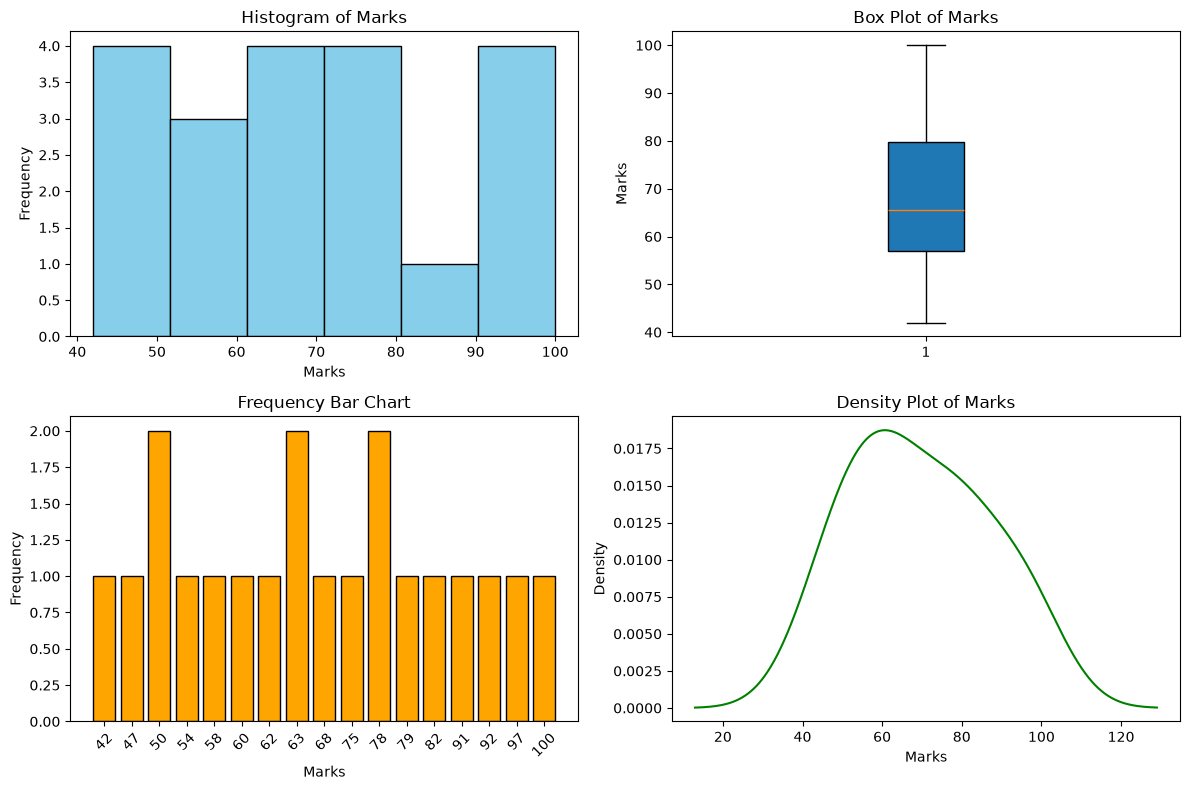

In [4]:
x = df["Marks"]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Histogram
axes[0, 0].hist(x, bins=6, color="skyblue", edgecolor="black")
axes[0, 0].set_title("Histogram of Marks")
axes[0, 0].set_xlabel("Marks")
axes[0, 0].set_ylabel("Frequency")

# 2. Box Plot
axes[0, 1].boxplot(x, patch_artist=True)
axes[0, 1].set_title("Box Plot of Marks")
axes[0, 1].set_ylabel("Marks")

# 3. Bar Chart (frequency of each distinct mark)
frequency = x.value_counts().sort_index()
axes[1, 0].bar(
    frequency.index.astype(str),
    frequency.values,
    color="orange",
    edgecolor="black"
)
axes[1, 0].set_title("Frequency Bar Chart")
axes[1, 0].set_xlabel("Marks")
axes[1, 0].set_ylabel("Frequency")
axes[1, 0].tick_params(axis="x", rotation=45)

# 4. Density Plot
x.plot(kind="density", ax=axes[1, 1], color="green")
axes[1, 1].set_title("Density Plot of Marks")
axes[1, 1].set_xlabel("Marks")
axes[1, 1].set_ylabel("Density")

plt.tight_layout()
plt.show()

In [5]:
x = df["Marks"]

# Skewness
skewness = stats.skew(x, bias=False)

# Excess kurtosis
excess_kurtosis = stats.kurtosis(
    x, fisher=True, bias=False
)

# Pearson kurtosis = excess kurtosis + 3
pearson_kurtosis = excess_kurtosis + 3

print("\nMEASURES OF SHAPE")
print("Skewness:", skewness)
print("Excess Kurtosis:", excess_kurtosis)
print("Pearson Kurtosis:", pearson_kurtosis)

# Simple interpretation
if skewness > 0.5:
    print("Distribution is positively skewed.")
elif skewness < -0.5:
    print("Distribution is negatively skewed.")
else:
    print("Distribution is approximately symmetric.")

if excess_kurtosis > 0:
    print("Positive excess kurtosis: heavier tails than normal.")
elif excess_kurtosis < 0:
    print("Negative excess kurtosis: lighter tails than normal.")
else:
    print("Zero excess kurtosis: normal-like kurtosis.")


MEASURES OF SHAPE
Skewness: 0.24126672841338753
Excess Kurtosis: -1.0049310921143428
Pearson Kurtosis: 1.9950689078856572
Distribution is approximately symmetric.
Negative excess kurtosis: lighter tails than normal.


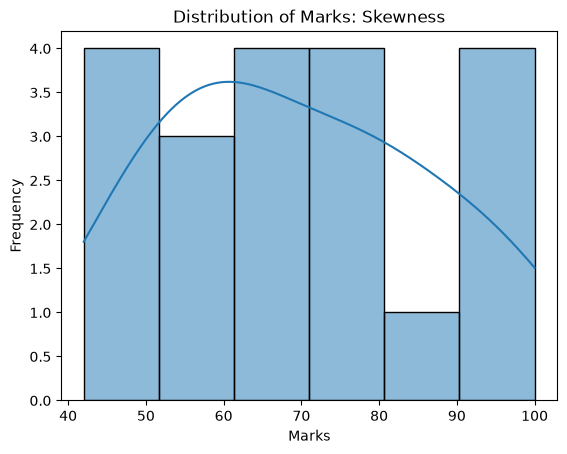

Skewness: 0.2412667284133876
Excess Kurtosis: -1.0049310921143433


In [8]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.histplot(df["Marks"], kde=True, bins=6)
plt.title("Distribution of Marks: Skewness")
plt.xlabel("Marks")
plt.ylabel("Frequency")
plt.show()

print("Skewness:", df["Marks"].skew())
print("Excess Kurtosis:", df["Marks"].kurtosis())

In [6]:
print("\nCOMPLETE SUMMARY")
print(df["Marks"].describe())


COMPLETE SUMMARY
count     20.000000
mean      69.450000
std       17.328027
min       42.000000
25%       57.000000
50%       65.500000
75%       79.750000
max      100.000000
Name: Marks, dtype: float64


In [7]:
summary = pd.Series({
    "Count": x.count(),
    "Mean": x.mean(),
    "Median": x.median(),
    "Mode(s)": str(x.mode().tolist()),
    "Minimum": x.min(),
    "Maximum": x.max(),
    "Range": data_range,
    "Sample Variance": sample_variance,
    "Sample Std Dev": sample_std,
    "Q1": q1,
    "Q2": q2,
    "Q3": q3,
    "IQR": iqr,
    "Mean Absolute Deviation": mad,
    "Coefficient of Variation (%)": cv,
    "Skewness": skewness,
    "Excess Kurtosis": excess_kurtosis
})

print(summary.to_string())

Count                                     20
Mean                                   69.45
Median                                  65.5
Mode(s)                         [50, 63, 78]
Minimum                                   42
Maximum                                  100
Range                                     58
Sample Variance                   300.260526
Sample Std Dev                     17.328027
Q1                                      57.0
Q2                                      65.5
Q3                                     79.75
IQR                                    22.75
Mean Absolute Deviation               14.695
Coefficient of Variation (%)       24.950363
Skewness                            0.241267
Excess Kurtosis                    -1.004931
